# 02: Model Comparison (Milestone 3)

This notebook compares a baseline with four learned models for my CT4101 project, using the same train/test split, cross-validation folds and metrics as notebook 01. It also answers the feedback I received on Milestone 2, which was that I needed to look into data balancing because of the severe class imbalance. I am grateful for that feedback, and section 2 onwards is built around it.

The notebook is organised as follows:
1. Setup
2. Data balancing techniques
3. Model settings and tuning
4. Results: does balancing help?
5. Results: model comparison
6. Decision threshold and confusion matrix
7. Error analysis and age-group fairness check
8. Draft conclusion and next steps

**The test set is not used anywhere in this notebook.** Every number below comes from 5-fold cross-validation on the training set. The test set stays untouched until the final comparison at Milestone 4.

The notebook needs `python src/download_data.py` to have been run once, and takes roughly 15 minutes on a 12-core laptop.

## 1. Setup

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_curve
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Make src/ importable whether the notebook is run from the repo root or notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from data import load_raw, prepare_features
from modelling import build_pipeline, cross_fitted_decisions, slice_metrics

RANDOM_STATE = 42
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9a9992", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10,
})
BLUE = "#2a78d6"
GREY = "#7a7972"

In [2]:
# The same split and folds as notebook 01, so results are directly comparable
df = load_raw()
X, y = prepare_features(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train))

num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(exclude="number").columns.tolist()
print("Train:", X_train.shape, " positive rate:", round(y_train.mean(), 4))

Train: (36168, 15)  positive rate: 0.117


## 2. Data balancing techniques
The purpose of this section is to set out how I have responded to the imbalance that was pointed out to me as part of the feedback received on Milestone 2. Only 11.7% of clients subscribed, which is roughly 7.5 "no" clients for every "yes". A model trained on this data can achieve a low loss by rarely predicting "yes", and notebook 01 showed exactly that: logistic regression labelled only 3.2% of clients as "yes".

I have compared five approaches, each applied to every model:

| Technique | What it does | Trade-off |
|---|---|---|
| **No balancing** | Trains on the data as it is. | The reference point. |
| **Class weighting** | Keeps every row but makes errors on "yes" clients count about 7.5 times more during fitting (`class_weight="balanced"`). | Not available for kNN. |
| **Random oversampling** | Repeats randomly chosen "yes" rows until the classes are equal. | Adds no new information and invites overfitting to the repeated rows. |
| **Random undersampling** | Discards randomly chosen "no" rows until the classes are equal. | Fast, but throws away about 87% of the "no" clients. |
| **SMOTE-NC** | Creates synthetic "yes" clients by interpolating numeric features between similar real clients and taking the most common category among them (Chawla et al., 2002). | Synthetic clients may not be realistic. |

I have used SMOTE-NC rather than plain SMOTE because nine of my features are categorical. Plain SMOTE applied to one-hot columns would create impossible clients, such as someone who is 40% married and 60% single.

**Avoiding leakage.** Balancing must only touch the data a model trains on. If I resampled before splitting, copies or blends of a validation client could end up in the training data, and the validation fold would no longer reflect the true 11.7% rate. I have therefore placed each sampler inside an `imblearn` `Pipeline` (Lemaitre et al., 2017; see `src/modelling.py`), which applies it during `fit` only. The table below shows the training portion of one fold under each technique. The validation portion of that fold is never resampled.

*Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. Journal of Artificial Intelligence Research, 16, 321-357.*
*Lemaitre, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python Toolbox to Tackle the Curse of Imbalanced Datasets in Machine Learning. Journal of Machine Learning Research, 18(17), 1-5.*

In [3]:
# previously_contacted is stored as a number but is really a yes/no category
smote_categorical = cat_features + ["previously_contacted"]

TECHNIQUES = {
    "No balancing": {},
    "Class weighting": {"class_weight": "balanced"},
    "Random oversampling": {"sampler": RandomOverSampler(random_state=RANDOM_STATE)},
    "Random undersampling": {"sampler": RandomUnderSampler(random_state=RANDOM_STATE)},
    "SMOTE-NC": {"sampler": SMOTENC(categorical_features=smote_categorical, random_state=RANDOM_STATE)},
}

# Show what each technique does to the training portion of one fold
train_idx, val_idx = folds[0]
scale_step = build_pipeline(None, num_features, cat_features).named_steps["scale"]
X_fold = scale_step.fit_transform(X_train.iloc[train_idx])
y_fold = y_train.iloc[train_idx]

rows = [{"Technique": "No balancing or class weighting", "No (0)": (y_fold == 0).sum(),
         "Yes (1)": (y_fold == 1).sum()}]
for name, technique in TECHNIQUES.items():
    if "sampler" in technique:
        _, y_resampled = clone(technique["sampler"]).fit_resample(X_fold, y_fold)
        rows.append({"Technique": name, "No (0)": (y_resampled == 0).sum(), "Yes (1)": (y_resampled == 1).sum()})
fold_counts = pd.DataFrame(rows).set_index("Technique")
fold_counts["Yes %"] = (fold_counts["Yes (1)"] / fold_counts.sum(axis=1) * 100).round(1)
print("Validation fold positive rate (never resampled):", round(y_train.iloc[val_idx].mean(), 4))
fold_counts

Validation fold positive rate (never resampled): 0.1169


,No (0),Yes (1),Yes %
Technique,,,
No balancing or class weighting,25549,3385,11.7
Random oversampling,25549,25549,50.0
Random undersampling,3385,3385,50.0
SMOTE-NC,25549,25549,50.0


## 3. Model settings and tuning
The purpose of this section is to define the models and how much tuning each one receives. The models are the ones set out in my proposal. Logistic regression stays at its default settings, as it is my simple baseline.

| Model | Fixed settings | Tuned using | Why |
|---|---|---|---|
| kNN | | `n_neighbors` (25, 75, 151), `weights` | A small k is noisy, and a large k is dominated by the majority class. |
| Decision tree | | `max_depth` (6, 10, 14, 20), `min_samples_leaf` (50, 100, 200) | Both limit how closely the tree can memorise the training data. |
| Random forest | 300 trees | `max_depth` (8, 14, none), `min_samples_leaf` (5, 20) | The number of trees only needs to be large enough, so I have fixed it. |
| Gradient boosting | `HistGradientBoostingClassifier` | `learning_rate` (0.03, 0.1), `max_leaf_nodes` (7, 15, 31), `max_iter` (100, 300) | These trade the number of boosting rounds against the size of each tree. |

I have kept these grids small on purpose, in line with the proportionate tuning asked for in the brief. Each grid is searched with `GridSearchCV` on the same 5 folds, and the setting with the highest PR-AUC is kept, as PR-AUC is my main metric.

I am tuning each model separately under each balancing technique. Tuning once without balancing and then adding the techniques would favour "No balancing", because the settings would have been chosen for it. F1 is computed at the default 0.5 threshold and again with a tuned threshold. The tuned version picks the threshold for each fold using the other four folds only (see `cross_fitted_decisions` in `src/modelling.py`).

In [4]:
# Each entry is (model with its fixed settings, the small grid searched for it)
candidates = {
    "Logistic regression (baseline)": (LogisticRegression(max_iter=1000), {}),
    "kNN": (KNeighborsClassifier(), {
        "model__n_neighbors": [25, 75, 151],
        "model__weights": ["uniform", "distance"],
    }),
    "Decision tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        "model__max_depth": [6, 10, 14, 20],
        "model__min_samples_leaf": [50, 100, 200],
    }),
    "Random forest": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE), {
        "model__max_depth": [8, 14, None],
        "model__min_samples_leaf": [5, 20],
    }),
    "Gradient boosting": (HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE), {
        "model__learning_rate": [0.03, 0.1],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__max_iter": [100, 300],
    }),
}
scoring = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "F1": "f1"}

In [5]:
# Oh boy, is this the slow cell of the notebook.
# Every model is tuned separately under every technique, so no technique is
# disadvantaged by settings that were chosen for a different one.
results, oof_proba, fold_scores, grid_results = [], {}, {}, {}
start = time.time()

for model_name, (estimator, grid) in candidates.items():
    for technique_name, technique in TECHNIQUES.items():
        # kNN has no class_weight option, so that combination does not exist
        if model_name == "kNN" and technique_name == "Class weighting":
            continue
        model = clone(estimator)
        if "class_weight" in technique:
            model.set_params(class_weight=technique["class_weight"])
        pipe = build_pipeline(model, num_features, cat_features, technique.get("sampler"))

        search = GridSearchCV(pipe, grid, cv=cv, scoring=scoring, refit=False, n_jobs=-1)
        search.fit(X_train, y_train)

        # The best setting is whichever scores the highest PR-AUC in cross-validation
        cv_res = search.cv_results_
        best = int(np.argmin(cv_res["rank_test_PR-AUC"]))
        best_params = cv_res["params"][best]

        # Out-of-fold probabilities: each row is predicted by a model that did not train on it
        proba = cross_val_predict(clone(pipe).set_params(**best_params), X_train, y_train,
                                  cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
        _, thresholds, tuned_f1 = cross_fitted_decisions(y_train, proba, folds)

        key = (model_name, technique_name)
        oof_proba[key] = proba
        grid_results[key] = pd.DataFrame(cv_res)
        fold_scores[key] = np.array([cv_res[f"split{i}_test_PR-AUC"][best] for i in range(5)])
        results.append({
            "Model": model_name,
            "Technique": technique_name,
            "Settings": ", ".join(f"{k.replace('model__', '')}={v}" for k, v in best_params.items()) or "defaults",
            "PR-AUC": cv_res["mean_test_PR-AUC"][best],
            "PR-AUC sd": cv_res["std_test_PR-AUC"][best],
            "ROC-AUC": cv_res["mean_test_ROC-AUC"][best],
            "ROC-AUC sd": cv_res["std_test_ROC-AUC"][best],
            "F1 at 0.5": cv_res["mean_test_F1"][best],
            "F1 at 0.5 sd": cv_res["std_test_F1"][best],
            "F1 tuned": tuned_f1.mean(),
            "F1 tuned sd": tuned_f1.std(),
            "Threshold": thresholds.mean(),
            "Mean predicted probability": proba.mean(),
        })
    print(f"{model_name} done after {(time.time() - start) / 60:.1f} min")

results = pd.DataFrame(results)

Logistic regression (baseline) done after 0.4 min


kNN done after 2.3 min


Decision tree done after 3.5 min


Random forest done after 9.4 min


Gradient boosting done after 13.1 min


In [6]:
# Check whether the best setting sits at the edge of its grid and whether more would help
for model_name in ["kNN", "Decision tree"]:
    top = grid_results[(model_name, "No balancing")].sort_values("rank_test_PR-AUC").head(3)
    print(model_name)
    print(top[["params", "mean_test_PR-AUC", "std_test_PR-AUC"]].round(4).to_string(index=False), "\n")

kNN
                                                   params  mean_test_PR-AUC  std_test_PR-AUC
 {'model__n_neighbors': 151, 'model__weights': 'uniform'}            0.3766           0.0107
  {'model__n_neighbors': 75, 'model__weights': 'uniform'}            0.3765           0.0090
{'model__n_neighbors': 151, 'model__weights': 'distance'}            0.3705           0.0116 

Decision tree
                                                  params  mean_test_PR-AUC  std_test_PR-AUC
{'model__max_depth': 20, 'model__min_samples_leaf': 100}            0.3930           0.0078
{'model__max_depth': 14, 'model__min_samples_leaf': 100}            0.3913           0.0097
 {'model__max_depth': 20, 'model__min_samples_leaf': 50}            0.3885           0.0137 



The best kNN and decision tree settings sit at the upper edge of their grids (`n_neighbors=151` and `max_depth=20`). I did not extend the grids further, because the top settings are separated by far less than the variation between folds, so the score has flattened out by that point. For the tree, `min_samples_leaf=100` is already restricting growth before the depth limit is reached.

## 4. Results: does balancing help?
The purpose of this section is to measure the effect of each balancing technique on three things: how well a model ranks clients (PR-AUC), how well it decides at the default 0.5 threshold (F1 at 0.5), and how well it decides when the threshold is tuned (F1 tuned). Each value is the mean over the 5 folds, and each panel has its own colour scale.

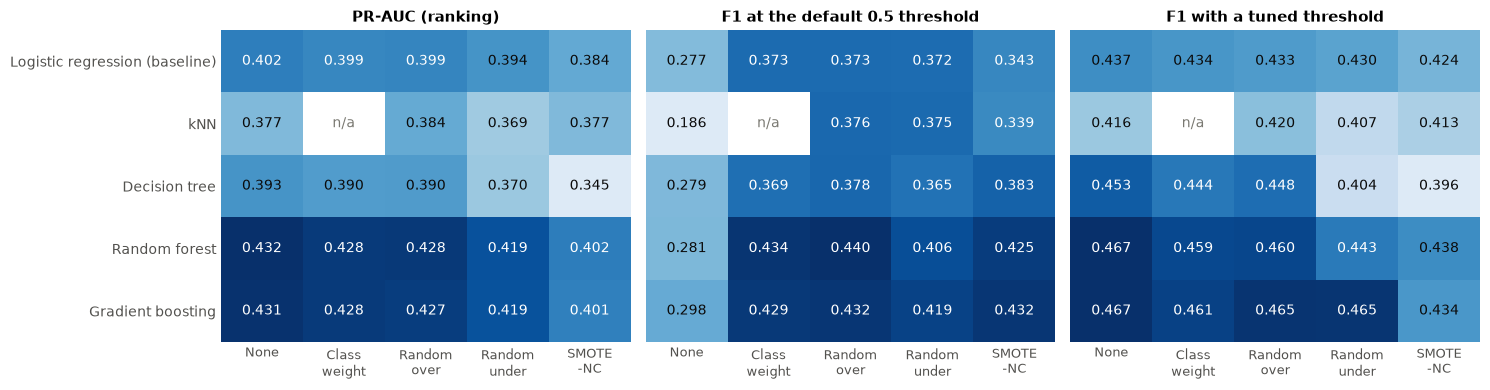

In [7]:
order_models = list(candidates)
order_techniques = list(TECHNIQUES)
panels = ["PR-AUC", "F1 at 0.5", "F1 tuned"]
panel_titles = ["PR-AUC (ranking)", "F1 at the default 0.5 threshold", "F1 with a tuned threshold"]
short_names = ["None", "Class\nweight", "Random\nover", "Random\nunder", "SMOTE\n-NC"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, metric, title in zip(axes, panels, panel_titles):
    table = results.pivot(index="Model", columns="Technique", values=metric).loc[order_models, order_techniques]
    values = table.to_numpy(dtype=float)
    low, high = np.nanmin(values), np.nanmax(values)
    ax.imshow(values, cmap="Blues", vmin=low - 0.15 * (high - low), vmax=high, aspect="auto")
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if np.isnan(values[i, j]):
                ax.text(j, i, "n/a", ha="center", va="center", color=GREY)
            else:
                dark = values[i, j] > low + 0.6 * (high - low)
                ax.text(j, i, f"{values[i, j]:.3f}", ha="center", va="center",
                        color="white" if dark else "#0b0b0b")
    ax.set_xticks(range(len(order_techniques)), short_names, fontsize=9)
    ax.set_yticks(range(len(order_models)), order_models)
    ax.set_title(title)
    ax.spines[:].set_visible(False)
    ax.tick_params(length=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "balancing_heatmaps.png", dpi=150)
plt.show()

The left panel and the middle panel tell different stories.

At the default 0.5 threshold, balancing helps considerably. Random forest moves from an F1 of 0.281 to 0.434 with class weighting and 0.440 with random oversampling, and kNN moves from 0.186 to 0.376.

For ranking, it does not. "No balancing" has the highest PR-AUC for four of the five models, the exception being kNN, which moves from 0.377 to 0.384 with random oversampling. To check this properly, the table below compares each technique with "No balancing" fold by fold. As the folds are identical, this is a fairer test than comparing the averages.

In [8]:
# Paired comparison: the folds are identical, so compare each technique with
# "No balancing" fold by fold, for the same model
rows = []
for technique_name in order_techniques[1:]:
    diffs = np.concatenate([
        fold_scores[(m, technique_name)] - fold_scores[(m, "No balancing")]
        for m in order_models if (m, technique_name) in fold_scores
    ])
    rows.append({
        "Technique": technique_name,
        "Mean PR-AUC change vs no balancing": round(diffs.mean(), 4),
        "Folds better": int((diffs > 0).sum()),
        "Folds worse": int((diffs < 0).sum()),
    })
pd.DataFrame(rows).set_index("Technique")

,Mean PR-AUC change vs no balancing,Folds better,Folds worse
Technique,,,
Class weighting,-0.0034,4,16
Random oversampling,-0.0014,8,17
Random undersampling,-0.0127,1,24
SMOTE-NC,-0.0251,3,22


In [9]:
# Balancing changes what the probabilities mean. Compare the average predicted
# probability with the true subscription rate
print("True positive rate in the training data:", round(y_train.mean(), 3))
results.pivot(index="Model", columns="Technique", values="Mean predicted probability").loc[
    order_models, order_techniques].round(3)

True positive rate in the training data: 0.117


Technique,No balancing,Class weighting,Random oversampling,Random undersampling,SMOTE-NC
Model,,,,,
Logistic regression (baseline),0.117,0.415,0.414,0.416,0.398
kNN,0.105,NaN,0.397,0.423,0.440
Decision tree,0.117,0.372,0.386,0.417,0.281
Random forest,0.117,0.383,0.370,0.414,0.333
Gradient boosting,0.117,0.390,0.388,0.414,0.266


No technique improves PR-AUC on average. Class weighting (-0.003) and random oversampling (-0.001) are close to neutral, as those changes are smaller than the variation between folds. Random undersampling (-0.013, worse in 24 of 25 comparisons) pays a price for discarding data. SMOTE-NC is the weakest (-0.025, worse in 22 of 25), which may indicate that synthetic clients built from mostly categorical features do not resemble real subscribers closely enough, although further investigation is needed to determine whether this is the cause.

The rightmost panel explains the gain at 0.5. Once the threshold is tuned, the unbalanced models match or beat the balanced ones: random forest and gradient boosting both reach an F1 of 0.467 with no balancing, against 0.459 and 0.461 with class weighting. I believe that balancing is mostly moving the operating point, by pushing predicted probabilities upwards so that more clients cross 0.5. The table above shows this directly. The average predicted probability rises from the true rate of 0.117 to around 0.37 to 0.42 for most balanced models, so their outputs can no longer be read as the likelihood of a client subscribing without being recalibrated.

From this analysis I can conclude that the imbalance is a problem for the default 0.5 decision rule rather than for the ranking the models learn. As such, I propose handling it with the following, as one parameter change does not solve imbalance:
- **stratified splits and folds**, so that every fold has the true class ratio;
- **PR-AUC as the main metric**, because it is not flattered by the majority class;
- **a tuned decision threshold**, chosen within cross-validation, in place of resampling.

## 5. Results: model comparison
The table below compares the baselines with each learned model under the same evaluation protocol. For each model it uses the configuration with the highest PR-AUC across the five balancing techniques. Values are the mean ± standard deviation over the 5 folds. `Threshold` is the average threshold used for `F1 tuned`. The table is also saved to `reports/model_comparison.csv`.

In [10]:
# Each model's best configuration (highest PR-AUC across the five techniques)
best_rows = results.loc[results.groupby("Model")["PR-AUC"].idxmax()].set_index("Model").loc[order_models]

# The majority-class baseline, under the same protocol
dummy_pipe = build_pipeline(DummyClassifier(strategy="most_frequent"), num_features, cat_features)
dummy = cross_validate(dummy_pipe, X_train, y_train, cv=cv, scoring=scoring)

def fmt(mean, sd):
    return f"{mean:.3f} ± {sd:.3f}"

table = [{"Model": "Majority class (baseline)", "Balancing": "n/a", "Main settings": "always predicts no",
          "PR-AUC": fmt(dummy["test_PR-AUC"].mean(), dummy["test_PR-AUC"].std()),
          "ROC-AUC": fmt(dummy["test_ROC-AUC"].mean(), dummy["test_ROC-AUC"].std()),
          "F1 at 0.5": fmt(dummy["test_F1"].mean(), dummy["test_F1"].std()),
          "F1 tuned": "n/a", "Threshold": "n/a"}]
for model_name, row in best_rows.iterrows():
    table.append({
        "Model": model_name, "Balancing": row["Technique"], "Main settings": row["Settings"],
        "PR-AUC": fmt(row["PR-AUC"], row["PR-AUC sd"]),
        "ROC-AUC": fmt(row["ROC-AUC"], row["ROC-AUC sd"]),
        "F1 at 0.5": fmt(row["F1 at 0.5"], row["F1 at 0.5 sd"]),
        "F1 tuned": fmt(row["F1 tuned"], row["F1 tuned sd"]),
        "Threshold": f"{row['Threshold']:.3f}",
    })
comparison = pd.DataFrame(table).set_index("Model")
comparison.to_csv(ROOT / "reports" / "model_comparison.csv")
comparison

,Balancing,Main settings,PR-AUC,ROC-AUC,F1 at 0.5,F1 tuned,Threshold
Model,,,,,,,
Majority class (baseline),n/a,always predicts no,0.117 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,n/a,n/a
Logistic regression (baseline),No balancing,defaults,0.402 ± 0.008,0.764 ± 0.003,0.277 ± 0.012,0.437 ± 0.004,0.189
kNN,Random oversampling,"n_neighbors=151, weights=uniform",0.384 ± 0.011,0.758 ± 0.005,0.376 ± 0.005,0.420 ± 0.010,0.641
Decision tree,No balancing,"max_depth=20, min_samples_leaf=100",0.393 ± 0.008,0.754 ± 0.008,0.279 ± 0.019,0.453 ± 0.009,0.259
Random forest,No balancing,"max_depth=14, min_samples_leaf=5",0.432 ± 0.014,0.787 ± 0.006,0.281 ± 0.011,0.467 ± 0.010,0.191
Gradient boosting,No balancing,"learning_rate=0.03, max_iter=100, max_leaf_nodes=31",0.431 ± 0.010,0.787 ± 0.005,0.298 ± 0.009,0.467 ± 0.003,0.188


The metric I am comparing is PR-AUC. Random forest (0.432) and gradient boosting (0.431) are the best two, followed by the logistic regression baseline (0.402), the decision tree (0.393) and kNN (0.384). All five are more than three times better than the majority-class baseline (0.117).

The two ensembles improve on logistic regression by about 0.03, which is more than twice the variation between folds. ROC-AUC gives the same order at the top (0.787 for both, against 0.764). It is worth noting that the single tree and kNN do not beat the untuned logistic regression on PR-AUC, which shows that added model complexity does not automatically pay off.

The gap between the two ensembles is another matter, as the check below shows.

In [11]:
learned = best_rows.sort_values("PR-AUC", ascending=False)
first, second = learned.index[:2]
gap = (fold_scores[(first, learned.loc[first, "Technique"])]
       - fold_scores[(second, learned.loc[second, "Technique"])])
print(f"Current best by PR-AUC: {first} ({learned.loc[first, 'Technique']})")
print(f"Runner-up: {second} ({learned.loc[second, 'Technique']})")
print("PR-AUC gap per fold:", gap.round(3), " mean:", round(gap.mean(), 4))

Current best by PR-AUC: Random forest (No balancing)
Runner-up: Gradient boosting (No balancing)
PR-AUC gap per fold: [-0.    -0.003  0.004 -0.01   0.014]  mean: 0.0009


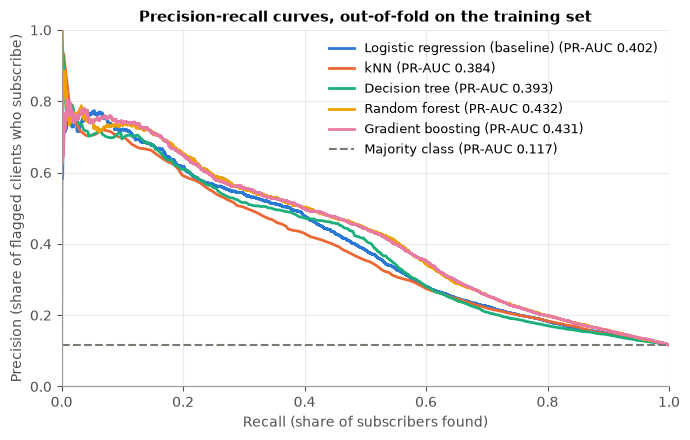

In [12]:
colours = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
fig, ax = plt.subplots(figsize=(7, 4.5))
for colour, (model_name, row) in zip(colours, best_rows.iterrows()):
    precision, recall, _ = precision_recall_curve(y_train, oof_proba[(model_name, row["Technique"])])
    ax.plot(recall, precision, color=colour, linewidth=2, label=f"{model_name} (PR-AUC {row['PR-AUC']:.3f})")
ax.axhline(y_train.mean(), color=GREY, linestyle="--", linewidth=1.5,
           label=f"Majority class (PR-AUC {y_train.mean():.3f})")
ax.set_xlabel("Recall (share of subscribers found)")
ax.set_ylabel("Precision (share of flagged clients who subscribe)")
ax.set_title("Precision-recall curves, out-of-fold on the training set")
ax.set_ylim(0, 1)
ax.set_xlim(0, 1)
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "precision_recall_curves.png", dpi=150)
plt.show()

The mean gap is only 0.001, and the sign of the gap changes from fold to fold, so I cannot separate these two models with this evidence. Random forest is my current best model only by a very narrow margin, and I have carried it forward as the highest-scoring model. The precision-recall curves agree, as the two ensembles overlap across almost the whole range.

## 6. Decision threshold and confusion matrix
The purpose of this section is to show what the tuned threshold changes in practice for the current best model. The predictions are out-of-fold, so each client is predicted by a model that did not train on them. Each threshold was chosen from the other four folds.

Thresholds chosen per fold: [0.214 0.179 0.187 0.193 0.179]


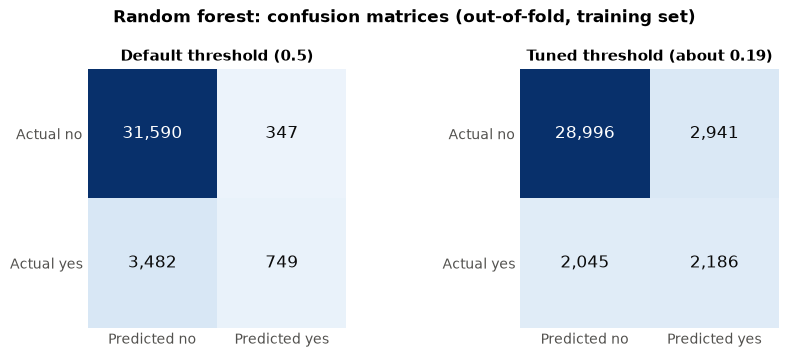

,clients,subscribers,actual rate,flagged rate,precision,recall,false positive rate
group,,,,,,,
All clients,36168,4231,0.117,0.142,0.426,0.517,0.092


In [13]:
best_model, best_technique = first, learned.loc[first, "Technique"]
best_proba = oof_proba[(best_model, best_technique)]
decisions, best_thresholds, _ = cross_fitted_decisions(y_train, best_proba, folds)
default_decisions = (best_proba >= 0.5).astype(int)
print("Thresholds chosen per fold:", best_thresholds.round(3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, preds, title in zip(axes, [default_decisions, decisions],
                            ["Default threshold (0.5)", f"Tuned threshold (about {best_thresholds.mean():.2f})"]):
    cm = confusion_matrix(y_train, preds)
    ax.imshow(cm, cmap="Blues", vmin=-cm.max() * 0.05, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() * 0.6 else "#0b0b0b")
    ax.set_xticks([0, 1], ["Predicted no", "Predicted yes"])
    ax.set_yticks([0, 1], ["Actual no", "Actual yes"])
    ax.set_title(title)
    ax.spines[:].set_visible(False)
    ax.tick_params(length=0)
fig.suptitle(f"{best_model}: confusion matrices (out-of-fold, training set)", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrices.png", dpi=150)
plt.show()

overall = slice_metrics(y_train, decisions, np.repeat("All clients", len(y_train)))
overall.round(3)

At 0.5, the model finds only 749 of the 4,231 subscribers. Lowering the threshold to about 0.19 finds 2,186, which is nearly three times as many, at the cost of 2,941 false positives rather than 347. Overall this gives a precision of 0.426 and a recall of 0.517, while 14.2% of clients are flagged.

It is worth noting that maximising F1 assumes that precision and recall matter equally. A real bank would set this threshold from the cost of a call and the value of a subscription, neither of which I have. The table below looks at the same model from the perspective of a limited call budget, which does not depend on a threshold.

In [14]:
# A bank would use the ranking to decide whom to call first
ranked = y_train.to_numpy()[np.argsort(-best_proba)]
rows = []
for share in [0.1, 0.2, 0.3, 0.5]:
    top = ranked[: int(len(ranked) * share)]
    rows.append({
        "Share of clients called": f"{share:.0%}",
        "Precision in that group": round(top.mean(), 3),
        "Share of all subscribers reached": round(top.sum() / ranked.sum(), 3),
    })
pd.DataFrame(rows).set_index("Share of clients called")

,Precision in that group,Share of all subscribers reached
Share of clients called,,
10%,0.491,0.419
20%,0.349,0.597
30%,0.268,0.686
50%,0.191,0.818


Calling the 20% of clients ranked highest would reach 59.7% of all subscribers, with a precision of 0.349, about three times the 0.117 expected from calling at random.

## 7. Error analysis and age-group fairness check
The purpose of this section is to identify where the current best model performs poorly. I have used recall as the main lens, because a missed subscriber is the most common error at the tuned threshold, and I have broken the results down by the features that showed the strongest patterns in notebook 01.

In [15]:
train_view = X_train.copy()
train_view["age group"] = pd.cut(X_train["age"], bins=[0, 29, 39, 49, 59, 120],
                                 labels=["Under 30", "30-39", "40-49", "50-59", "60+"])

slices = {col: slice_metrics(y_train, decisions, train_view[col])
          for col in ["poutcome", "contact", "month", "job"]}
for col, table in slices.items():
    print(col)
    display(table.sort_values("recall").round(3))

# Where do the missed subscribers actually sit?
missed = (y_train.to_numpy() == 1) & (decisions == 0)
print("Missed subscribers:", missed.sum())
print("Share with no previous campaign (poutcome unknown):",
      round((X_train["poutcome"].to_numpy()[missed] == "unknown").mean(), 3))
print("Share with contact unknown:", round((X_train["contact"].to_numpy()[missed] == "unknown").mean(), 3))
unknown_contact = X_train["contact"] == "unknown"
print("Share of contact-unknown rows from May or June:",
      round(X_train.loc[unknown_contact, "month"].isin(["may", "jun"]).mean(), 3))

poutcome


,clients,subscribers,actual rate,flagged rate,precision,recall,false positive rate
group,,,,,,,
unknown,29589,2729,0.092,0.083,0.382,0.343,0.057
failure,3889,478,0.123,0.250,0.298,0.607,0.200
other,1485,245,0.165,0.333,0.364,0.735,0.253
success,1205,779,0.646,1.000,0.646,1.000,1.000


contact


,clients,subscribers,actual rate,flagged rate,precision,recall,false positive rate
group,,,,,,,
unknown,10386,427,0.041,0.008,0.259,0.049,0.006
cellular,23465,3481,0.148,0.191,0.435,0.560,0.127
telephone,2317,323,0.139,0.241,0.383,0.663,0.173


month


,clients,subscribers,actual rate,flagged rate,precision,recall,false positive rate
group,,,,,,,
may,11062,739,0.067,0.041,0.350,0.215,0.029
jul,5537,513,0.093,0.056,0.452,0.273,0.034
nov,3143,316,0.101,0.087,0.426,0.367,0.055
aug,4986,545,0.109,0.113,0.398,0.409,0.076
feb,2078,349,0.168,0.219,0.378,0.493,0.164
jan,1119,114,0.102,0.162,0.331,0.526,0.120
jun,4237,441,0.104,0.146,0.433,0.608,0.092
apr,2394,468,0.195,0.308,0.431,0.679,0.218
dec,178,84,0.472,0.871,0.503,0.929,0.819


job


,clients,subscribers,actual rate,flagged rate,precision,recall,false positive rate
group,,,,,,,
blue-collar,7830,571,0.073,0.044,0.403,0.243,0.028
entrepreneur,1186,101,0.085,0.069,0.402,0.327,0.045
services,3348,298,0.089,0.068,0.465,0.356,0.040
technician,6068,663,0.109,0.113,0.422,0.437,0.073
self-employed,1243,142,0.114,0.134,0.425,0.500,0.087
admin.,4141,509,0.123,0.153,0.411,0.513,0.103
housemaid,1013,85,0.084,0.139,0.312,0.518,0.105
management,7511,1041,0.139,0.172,0.448,0.555,0.110
unemployed,1024,158,0.154,0.196,0.438,0.557,0.130


Missed subscribers: 2045
Share with no previous campaign (poutcome unknown): 0.876
Share with contact unknown: 0.199
Share of contact-unknown rows from May or June: 0.961


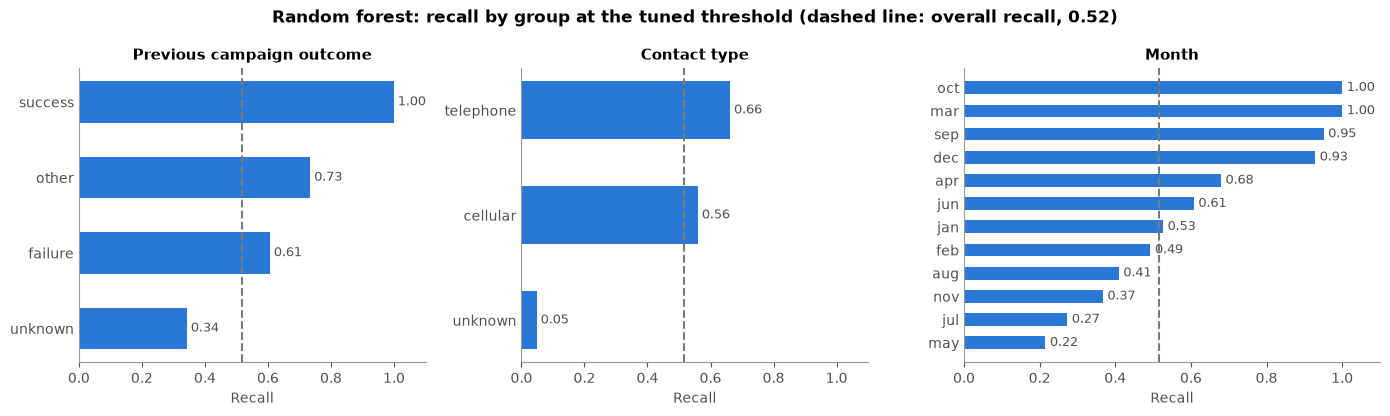

In [16]:
# Recall per group: where does the model miss the most subscribers?
plot_groups = {"poutcome": "Previous campaign outcome", "contact": "Contact type", "month": "Month"}
overall_recall = overall["recall"].iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2),
                         gridspec_kw={"width_ratios": [1, 1, 1.2]}, sharex=True)
for ax, (col, title) in zip(axes, plot_groups.items()):
    part = slices[col].sort_values("recall")
    ax.barh(part.index, part["recall"], color=BLUE, height=0.55)
    ax.axvline(overall_recall, color=GREY, linestyle="--", linewidth=1.5)
    for pos, value in enumerate(part["recall"]):
        ax.text(value + 0.012, pos, f"{value:.2f}", va="center", fontsize=9, color="#52514e")
    ax.set_title(title)
    ax.set_xlim(0, 1.1)
    ax.set_xlabel("Recall")
    ax.tick_params(axis="y", length=0)
fig.suptitle(f"{best_model}: recall by group at the tuned threshold (dashed line: overall recall, {overall_recall:.2f})",
             fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "recall_by_group.png", dpi=150)
plt.show()

The model performs poorly in three places.

**Clients with no campaign history.** When `poutcome` is `unknown`, recall is only 0.343, and this group holds 88% of all missed subscribers. These clients have no record of past behaviour, so the model has little to go on. This is the largest weakness in the model. At the other extreme, the model flags every client whose previous outcome was a success. This means it is applying something close to a single rule for this group, which is reasonable given the 64.6% subscription rate, but it does not distinguish between those clients at all.

**Clients with an unknown contact type.** Recall is 0.049, and only 0.8% of these clients are flagged. Their subscription rate is low (4.1%), and 96% of them were called in May or June. I believe this reflects a period in which the bank did not record the contact type, so the model may be learning a data-collection effect rather than anything about those clients.

**The busiest and quietest months.** Recall is 0.215 in May, the busiest month, while in March and October the model flags nearly everybody (false positive rates of 0.990 and 0.982). The month is working as a proxy for how the campaigns were run, which may not hold in future years. I noted this as a risk in notebook 01, and this analysis supports that concern.

Job shows a smaller version of the same pattern, with recall of 0.243 for blue-collar clients and 0.900 for students, in line with their subscription rates of 7.3% and 28.9%.

### 7.1 Age-group fairness check
This is the check set out in my proposal. I have compared error rates across age groups using the same predictions.

,clients,subscribers,actual rate,flagged rate,precision,recall,false positive rate
group,,,,,,,
Under 30,4270,749,0.175,0.276,0.402,0.633,0.200
30-39,14481,1534,0.106,0.106,0.419,0.417,0.069
40-49,9323,854,0.092,0.079,0.474,0.407,0.046
50-59,6647,606,0.091,0.098,0.429,0.460,0.062
60+,1447,488,0.337,0.716,0.430,0.912,0.616


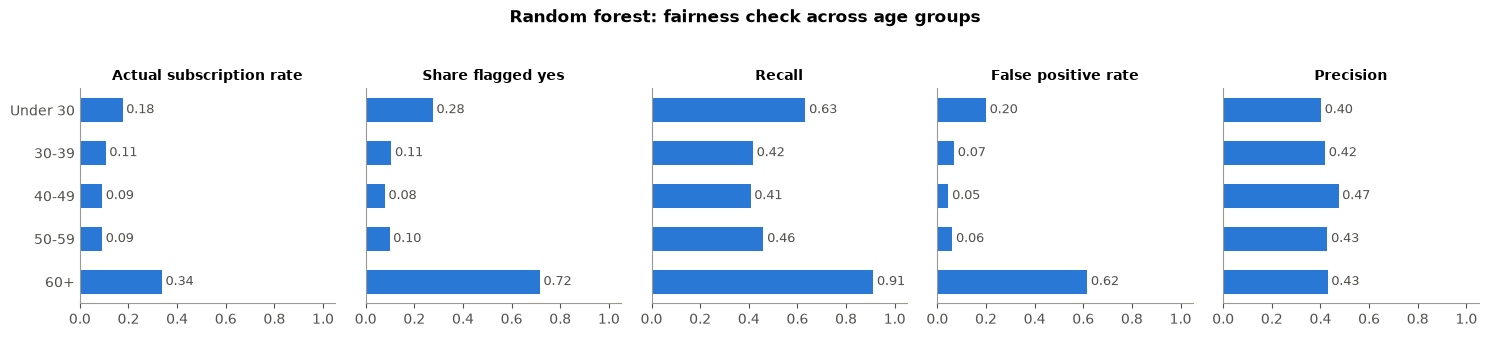

In [17]:
age_slices = slice_metrics(y_train, decisions, train_view["age group"])
display(age_slices.round(3))

panels = {"actual rate": "Actual subscription rate", "flagged rate": "Share flagged yes",
          "recall": "Recall", "false positive rate": "False positive rate", "precision": "Precision"}
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2), sharey=True, sharex=True)
for ax, (col, title) in zip(axes, panels.items()):
    ax.barh(age_slices.index.astype(str), age_slices[col], color=BLUE, height=0.55)
    for pos, value in enumerate(age_slices[col]):
        ax.text(value + 0.015, pos, f"{value:.2f}", va="center", fontsize=9, color="#52514e")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 1.05)
    ax.tick_params(axis="y", length=0)
axes[0].invert_yaxis()
fig.suptitle(f"{best_model}: fairness check across age groups", fontweight="bold", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "age_group_fairness.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# Is age itself driving this, or do older clients differ in other ways?
quiet_months = train_view["month"].isin(["mar", "sep", "oct", "dec"])
pd.DataFrame({
    "Retired": (train_view["job"] == "retired").groupby(train_view["age group"], observed=True).mean(),
    "Called in Mar/Sep/Oct/Dec": quiet_months.groupby(train_view["age group"], observed=True).mean(),
    "Previous campaign succeeded": (train_view["poutcome"] == "success").groupby(train_view["age group"], observed=True).mean(),
}).round(3)

,Retired,Called in Mar/Sep/Oct/Dec,Previous campaign succeeded
age group,,,
Under 30,0.001,0.069,0.048
30-39,0.001,0.034,0.028
40-49,0.010,0.028,0.026
50-59,0.122,0.033,0.026
60+,0.610,0.234,0.126


Precision is fairly even across age groups, ranging from 0.402 to 0.474, so a flagged client is about as likely to subscribe regardless of age. The other error rates are not even. Clients aged 60 and over have a recall of 0.912 and a false positive rate of 0.616, compared with recall between 0.407 and 0.460 and false positive rates between 0.046 and 0.069 for clients aged 30 to 59. Clients under 30 sit in between, with a recall of 0.633 and a false positive rate of 0.200.

Part of this is genuine, since 33.7% of clients aged 60 and over subscribed. However, the model flags 71.6% of them, which is more than twice that rate. The table above suggests a reason. Clients aged 60 and over are mostly retired (61.0%) and are far more often found in the high-rate months (23.4%, compared with about 3% for those aged 30 to 59) and among previous successes (12.6%, compared with under 3%). As such, the model may be picking up on the way these clients were targeted, and further investigation is needed to determine how much of the effect comes from age itself.

In practice, a model used this way would direct many unsuccessful calls towards older clients. As term deposits are a financial product, I consider this to be a real risk of unwanted sales pressure on older clients, and I will address it in my final report.

## 8. Draft conclusion and next steps
**Current best model.** Random forest with 300 trees, `max_depth=14`, `min_samples_leaf=5` and no resampling, using a decision threshold of about 0.19.

**Evidence.** In 5-fold cross-validation on the training set it has a PR-AUC of 0.432 ± 0.014 against 0.402 for the logistic regression baseline and 0.117 for the majority class, a ROC-AUC of 0.787 and a tuned F1 of 0.467. Gradient boosting is effectively tied with it (PR-AUC 0.431, tuned F1 0.467), and I can conclude that the data does not separate these two models.

**Data balancing.** I tested class weighting, random oversampling, random undersampling and SMOTE-NC across all models, inside the cross-validation folds. They improve F1 at the default threshold considerably (0.281 to 0.440 for random forest), but none of them improves PR-AUC on average, and a tuned threshold achieves a higher F1 without distorting the probabilities. I have therefore kept threshold tuning as the way of handling imbalance for the current best model.

**Limitations.**
- The model finds few of the clients with no campaign history, where most of the missed subscribers are.
- `month` and `contact` appear to reflect how the campaigns were run, so performance on a future campaign could be lower. The random split does not test for this.
- These scores are likely to be slightly optimistic, because the same folds were used to choose the settings and report the results. The test set will give a cleaner estimate.
- The F1-based threshold treats precision and recall as equally important, which is an assumption and not a business cost.
- Error rates differ substantially across age groups, with clients aged 60 and over flagged far more often.

**Next steps for Milestone 4.** I propose the following:
- run the final comparison once on the held-out test set, using the settings and threshold fixed through cross-validation;
- add a permutation-importance analysis to interpret the model;
- test how much performance and the age-group gap change when `age` and `month` are removed;
- check how well the model's probabilities are calibrated;
- write the final report, README and record the demo video.

Thank you for reading, and I look forward to developing this further for the final portfolio.